In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb

这里的特征工程策略基于 Boosting 思想  
逐层增加模型复杂度，用模型表现的变化来推断数据中存在哪些特征关系

用深度=1的树：
- 每棵树只能根据单个特征进行一次划分，所以模型只能学习单变量与目标变量的关系
- 可以通过观察特征重要性来发现最关键的单个特征，想想这些预测能力强的单个特征如何转换，然后把新特征再放到 CV 里面跑看 Sharpe 有没有提高 

用深度=2的树：
- 现在模型可以根据一个特征再在某个子区域用另一个特征做划分
- 这样模型可以捕捉两个特征之间的交互效应

In [2]:
train = (
    pd.read_csv("../Datasets/train.csv")
    .rename(columns={"market_forward_excess_returns": "target"})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != "date_id"]
train[cols_to_cast] = train[cols_to_cast].astype(float)

train

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9016,9016,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.208995,0.484788,0.717308,0.677249,-0.327455,0.083995,-0.380452,-0.000015,0.000151,-0.000477
9017,9017,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.082011,0.482804,1.001028,0.596561,-0.372979,0.094246,-0.427355,-0.005199,0.000150,-0.005661
9018,9018,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.334656,0.486772,0.894502,0.656746,-0.282024,0.090608,-0.381337,0.005930,0.000150,0.005467
9019,9019,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.163360,0.492725,1.117639,0.674603,-0.445261,0.106481,-0.477635,0.008173,0.000150,0.007710


## Create Feature DataFrame

`risk_free_rate` 得 shift(1) 避免未来信息，因为今天的 risk_free_rate 明天才知道

In [3]:
feature_df = train.copy()

# Feature groups
M_cols = [c for c in feature_df.columns if c.startswith('M')]
E_cols = [c for c in feature_df.columns if c.startswith('E')]
I_cols = [c for c in feature_df.columns if c.startswith('I')]
P_cols = [c for c in feature_df.columns if c.startswith('P')]
V_cols = [c for c in feature_df.columns if c.startswith('V')]
S_cols = [c for c in feature_df.columns if c.startswith('S')]
D_cols = [c for c in feature_df.columns if c.startswith('D')]

# Lagged features
feature_df['lagged_risk_free_rate'] = feature_df['risk_free_rate'].shift(1)
feature_df['lagged_forward_returns'] = feature_df['forward_returns'].shift(1)
feature_df['lagged_target'] = feature_df['target'].shift(1)

# New engineered M9 features
feature_df['M9_lt_neg183333'] = (feature_df['M9'] < -0.183333).astype(int)
feature_df['M9_lt_neg182703'] = (feature_df['M9'] < -0.182703).astype(int)
feature_df['M9_gt_pos677588'] = (feature_df['M9'] > 0.677588).astype(int)
# feature_df['M9_lt_neg757914'] = (feature_df['M9'] < -0.757914).astype(int)  # adding this did not improve Sharpe; stayed at 1.003321
# feature_df['M9_lt_neg768843'] = (feature_df['M9'] < -0.768843).astype(int)  # adding this lowered Sharpe to 1.003185
feature_df['M9_lt_neg683643'] = (feature_df['M9'] < -0.683643).astype(int)  # adding only this (without the previous 2) improved Sharpe to 1.003899
feature_df['M9_lt_neg768800'] = (feature_df['M9'] < -0.768800).astype(int)  # adding this improved Sharpe to 1.003912
feature_df['M9_gt_pos827470'] = (feature_df['M9'] > 0.827470).astype(int)  # adding this improved Sharpe to 1.005990
# feature_df['M9_lt_neg760046'] = (feature_df['M9'] < -0.760046).astype(int)  # adding this lowered Sharpe to 1.005827
# feature_df['M9_gt_pos018147'] = (feature_df['M9'] > 0.018147).astype(int)  # adding this lowered Sharpe to 1.005943
# feature_df['M9_gt_pos562128'] = (feature_df['M9'] > 0.562128).astype(int)  # adding this lowered Sharpe to 1.005891


# Anonymous & lagged features
anonymous_features = M_cols + E_cols + I_cols + P_cols + V_cols + S_cols + D_cols

lagged_features = [
    'lagged_risk_free_rate',
    'lagged_forward_returns',
    'lagged_target'
]

engineered_M9_features = [
    'M9_lt_neg183333',
    'M9_lt_neg182703',
    'M9_gt_pos677588',
    'M9_lt_neg683643',
    'M9_lt_neg768800',
    'M9_gt_pos827470',
    'M9_gt_pos562128'
]

# Final feature list
features = anonymous_features + lagged_features + engineered_M9_features

print("Number of features:", len(features))

Number of features: 104


## Day Forward-Chaining Nested Cross Validation
队友提到了这种模型驱动的特征工程方法有数据窥探的风险，于是想了用 nested CV 尽可能的避免这个问题
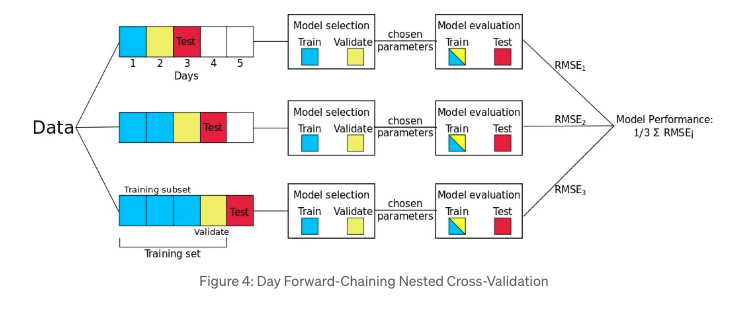

用 inner folds 了解特征，做 feature selection 和 transformation，不看 outer folds  
outer folds 完全不参与特征工程  
outer folds 只有在最后评估时才用

In [4]:
DATES = feature_df['date_id'].unique()
START_DATE_ID = int(DATES[0])
print('Start date_id:', START_DATE_ID)
END_DATE_ID = int(DATES[-1])
print('End date_id:', END_DATE_ID)
N_DATES = END_DATE_ID - START_DATE_ID + 1
print('Total number of trading days in the feature DataFrame:', N_DATES)

Start date_id: 0
End date_id: 9020
Total number of trading days in the feature DataFrame: 9021


Inner folds 有大量重叠的数据，希望的是能覆盖所有 market regimes；而 outer folds 则不能重叠太多，因为要测试特征在不同的市场环境下的真实表现

In [5]:
# purge 为了避免构建上面 lag 特征的数据泄露问题
# 其实 purge=1 就足够了因为都是 shift(1)，并且不打算再加入其他时序特征
PURGE = 2
OUTER_TRAIN_SIZE = 252 * 5  # 5 years
OUTER_TEST_SIZE = 126  # 6 months
INNER_FOLDS = 5
INNER_TRAIN_SIZE = 252 * 3  # 3 year
INNER_VAL_SIZE = OUTER_TEST_SIZE  # 6 months

# OUTER LOOP
OUTER_FOLDS = ((N_DATES - OUTER_TRAIN_SIZE - PURGE - OUTER_TEST_SIZE) // OUTER_TEST_SIZE) + 1
print("Number of Outer Folds:", OUTER_FOLDS)

for outer_i in range(OUTER_FOLDS):
    outer_train_start = START_DATE_ID + outer_i * OUTER_TEST_SIZE
    outer_train_end = outer_train_start + OUTER_TRAIN_SIZE - 1
    outer_test_start = outer_train_end + PURGE + 1
    if outer_i == OUTER_FOLDS - 1:
        outer_test_end = END_DATE_ID
    else:
        outer_test_end = outer_test_start + OUTER_TEST_SIZE - 1

    print(
        f"\nOuter Fold {outer_i+1}: "
        f"Train {outer_train_start}–{outer_train_end} "
        f"(len={outer_train_end - outer_train_start + 1}) | "
        f"Test {outer_test_start}–{outer_test_end} "
        f"(len={outer_test_end - outer_test_start + 1})"
    )

    # INNER SPLITS
    outer_train_len = outer_train_end - outer_train_start + 1
    STEP = 93

    for inner_i in range(INNER_FOLDS):
        # rolling inner training window
        inner_train_start = outer_train_start + inner_i * STEP
        inner_train_end = inner_train_start + INNER_TRAIN_SIZE - 1

        # validation window right after train
        inner_val_start = inner_train_end + PURGE + 1
        inner_val_end = inner_val_start + INNER_VAL_SIZE - 1

        # adjust last inner fold to hit outer_train_end exactly
        if inner_i == INNER_FOLDS - 1:
            inner_val_end = outer_train_end
            inner_val_start = inner_val_end - INNER_VAL_SIZE + 1
            inner_train_end = inner_val_start - PURGE - 1
            inner_train_start = inner_train_end - INNER_TRAIN_SIZE + 1

        print(f"  Inner Fold {inner_i+1}: "
              f"Train {inner_train_start}–{inner_train_end} (len={inner_train_end - inner_train_start + 1})"
              f" | Val {inner_val_start}–{inner_val_end} (len={inner_val_end - inner_val_start + 1})")

Number of Outer Folds: 61

Outer Fold 1: Train 0–1259 (len=1260) | Test 1262–1387 (len=126)
  Inner Fold 1: Train 0–755 (len=756) | Val 758–883 (len=126)
  Inner Fold 2: Train 93–848 (len=756) | Val 851–976 (len=126)
  Inner Fold 3: Train 186–941 (len=756) | Val 944–1069 (len=126)
  Inner Fold 4: Train 279–1034 (len=756) | Val 1037–1162 (len=126)
  Inner Fold 5: Train 376–1131 (len=756) | Val 1134–1259 (len=126)

Outer Fold 2: Train 126–1385 (len=1260) | Test 1388–1513 (len=126)
  Inner Fold 1: Train 126–881 (len=756) | Val 884–1009 (len=126)
  Inner Fold 2: Train 219–974 (len=756) | Val 977–1102 (len=126)
  Inner Fold 3: Train 312–1067 (len=756) | Val 1070–1195 (len=126)
  Inner Fold 4: Train 405–1160 (len=756) | Val 1163–1288 (len=126)
  Inner Fold 5: Train 502–1257 (len=756) | Val 1260–1385 (len=126)

Outer Fold 3: Train 252–1511 (len=1260) | Test 1514–1639 (len=126)
  Inner Fold 1: Train 252–1007 (len=756) | Val 1010–1135 (len=126)
  Inner Fold 2: Train 345–1100 (len=756) | Val 110

In [6]:
def get_day_forward_chaining_nested_cv(
    dates, purge, outer_train_size, outer_test_size, 
    inner_folds, inner_train_size, inner_val_size, step
):
    """
    Generates indices for Day Forward-Chaining Nested CV
    """
    
    start_date_id = int(dates[0])
    end_date_id = int(dates[-1])
    n_dates = end_date_id - start_date_id + 1

    # OUTER LOOP
    outer_folds_count = ((n_dates - outer_train_size - purge - outer_test_size) // outer_test_size) + 1
    
    for outer_i in range(outer_folds_count):
        outer_train_start = start_date_id + outer_i * outer_test_size
        outer_train_end = outer_train_start + outer_train_size - 1
        outer_test_start = outer_train_end + purge + 1

        # adjust last outer fold to hit last date_id exactly
        if outer_i == outer_folds_count - 1:
            outer_test_end = end_date_id
        else:
            outer_test_end = outer_test_start + outer_test_size - 1

        outer_train_idx = (outer_train_start, outer_train_end)
        outer_test_idx = (outer_test_start, outer_test_end)
        
        # INNER SPLITS
        inner_splits = []

        for inner_i in range(inner_folds):
            inner_train_start = outer_train_start + inner_i * step
            inner_train_end = inner_train_start + inner_train_size - 1
            inner_val_start = inner_train_end + purge + 1
            inner_val_end = inner_val_start + inner_val_size - 1

            # Adjust last inner fold to hit outer_train_end exactly
            if inner_i == inner_folds - 1:
                inner_val_end = outer_train_end
                inner_val_start = inner_val_end - inner_val_size + 1
                inner_train_end = inner_val_start - purge - 1
                inner_train_start = inner_train_end - inner_train_size + 1

            inner_train_idx = (int(inner_train_start), int(inner_train_end))
            inner_val_idx = (int(inner_val_start), int(inner_val_end))
            inner_splits.append((inner_train_idx, inner_val_idx))
            
        yield outer_train_idx, outer_test_idx, inner_splits

In [7]:
# Initialize the generator
cv_generator = get_day_forward_chaining_nested_cv(
    dates=DATES,
    purge=PURGE,
    outer_train_size=OUTER_TRAIN_SIZE,
    outer_test_size=OUTER_TEST_SIZE,
    inner_folds=INNER_FOLDS,
    inner_train_size=INNER_TRAIN_SIZE,
    inner_val_size=INNER_VAL_SIZE,
    step=93
)

评估 inner folds 的表现时，使用比赛官方提供的 Sharpe metric  
训练的 target 是 `market_forward_excess_returns`，scoring 用的是`forward_returns`和`risk_free_rate`
> solution['strategy_returns'] = solution['risk_free_rate'] * (1 - solution['position']) + solution['position'] * solution['forward_returns']

In [8]:
from scoring_metric import score, ParticipantVisibleError
print('Competition metric imported successfully!')

Competition metric imported successfully!


In [9]:
PARAMS = {
    'n_estimators': 500,
    'max_depth': 1,
    'learning_rate': 0.05,
    'n_jobs': -1,
    'random_state': 42
}

In [10]:
def run_day_forward_chaining_nested_cv(
    feature_df, features, cv_generator, model, params, 
    signal_multiplier=105, verbose=True
):

    inner_scores_dict = {}
    inner_models_dict = {}
    inner_val_data_dict = {}
    mean_inner_scores_list = []
    preds_dict = {}

    for outer_i, (outer_train_idx, outer_test_idx, inner_splits) in enumerate(cv_generator, start=1):
        if verbose:
            print(f"\n===== OUTER FOLD {outer_i} =====")

        # Build outer fold masks
        outer_train_mask = feature_df['date_id'].between(outer_train_idx[0], outer_train_idx[1])
        outer_test_mask = feature_df['date_id'].between(outer_test_idx[0], outer_test_idx[1])

        X_train_outer = feature_df.loc[outer_train_mask, features]
        y_train_outer = feature_df.loc[outer_train_mask, 'target']
        X_test_outer = feature_df.loc[outer_test_mask,  features]
        solution_outer = feature_df.loc[outer_test_mask, ['forward_returns', 'risk_free_rate']].copy()

        # Create storage for this outer fold
        inner_models_dict[outer_i] = []
        inner_val_data_dict[outer_i] = []
        inner_scores_dict[outer_i] = []
        preds_dict[outer_i] = []

        # INNER FOLD LOOP
        for inner_j, (inner_train_idx, inner_val_idx) in enumerate(inner_splits, start=1):

            # Build inner masks
            inner_train_mask = feature_df['date_id'].between(inner_train_idx[0], inner_train_idx[1])
            inner_val_mask = feature_df['date_id'].between(inner_val_idx[0], inner_val_idx[1])

            assert inner_train_idx[1] < inner_val_idx[0], "Leakage: inner train/val overlapping!"

            X_train_inner = feature_df.loc[inner_train_mask, features]
            y_train_inner = feature_df.loc[inner_train_mask, 'target']
            X_val_inner = feature_df.loc[inner_val_mask, features]
            y_val_inner = feature_df.loc[inner_val_mask, 'target']  # this is not explicitly used
            
            solution_inner = feature_df.loc[inner_val_mask, ['forward_returns', 'risk_free_rate']].copy()

            assert X_train_inner.shape == (756, len(features)), "Inner train shape incorrect"
            assert X_val_inner.shape == (126, len(features)), "Inner validation shape incorrect"

            # Train inner model
            model_inner = model(**params)
            model_inner.fit(X_train_inner, y_train_inner)

            # Store the inner model and validation data
            inner_models_dict[outer_i].append(model_inner)

            inner_val_data_dict[outer_i].append({
                "X_val": X_val_inner.copy(),
                "y_val": y_val_inner.copy(),
                "solution": solution_inner.copy()
            })

            # Score inner fold
            preds_inner = model_inner.predict(X_val_inner)
            preds_dict[outer_i].append(preds_inner)
            position_inner = np.clip(preds_inner * signal_multiplier + 1, 0, 2)
            submission_inner = pd.DataFrame({'prediction': position_inner}, index=X_val_inner.index)

            score_inner = score(solution_inner, submission_inner, 'index')
            inner_scores_dict[outer_i].append(score_inner)

        # Mean Sharpe of this outer fold
        mean_score = np.mean(inner_scores_dict[outer_i])
        mean_inner_scores_list.append(mean_score)
        
        if verbose:
            print(f"\nMean Inner Sharpe (Outer Fold {outer_i}): "
                  f"{mean_score:.6f}")

        # OUTER MODEL
        # DO NOT USE IT AT FEATURE ENGINEERING STAGE; FOR FINAL EVALUATION ONLY
        model_outer = model(**params)
        model_outer.fit(X_train_outer, y_train_outer)

        preds_outer = model_outer.predict(X_test_outer)
        position_outer = np.clip(preds_outer * signal_multiplier + 1, 0, 2)
        submission_outer = pd.DataFrame({'prediction': position_outer}, index=X_test_outer.index)

        # Compute outer score but do NOT store it
        _ = score(solution_outer, submission_outer, 'index')

    overall_mean_score = np.mean(mean_inner_scores_list)
    print("\n" + "="*30)
    print(f"OVERALL MEAN CV SCORE: {overall_mean_score:.6f}")
    print("="*30)

    # Return everything needed for SHAP analysis later
    return {
        'inner_scores_dict': inner_scores_dict,
        'inner_models_dict': inner_models_dict,
        'inner_val_data_dict': inner_val_data_dict,
        'preds_dict': preds_dict
    }

5个存储变量的的解释说明：
1. `inner_scores_dict`: 用来存储每一个 outer fold 里面每一个 inner fold 的 Sharpe scores  
   为了计算每一个 outer fold 的 mean inner Sharpe
2. `inner_models_dict`: 用来存储每一个 outer fold 里面每一个 inner fold 的模型  
   为了之后计算 SHAP
3. `inner_val_data_dict`: 用来存储每一个 inner fold 的验证集数据（`X_val`, `y_val`) 和真实的 (`forward_returns` + `risk_free_rate`)  
   可以用来 debug 预测值，比较真实和预测的值等
4. `mean_inner_scores_list`: 用来存储每一个 outer fold 的 Mean Inner Sharpe  
   为了最后计算 Overall Mean CV Score
5. `preds_dict`: 用来存储每个 outer fold 下所有 inner fold 的预测值  
   为了之后看 prediction 的分布来确认 `signal_multiplier`取什么值

In [11]:
results = run_day_forward_chaining_nested_cv(feature_df, features, cv_generator, xgb.XGBRegressor, PARAMS)


===== OUTER FOLD 1 =====

Mean Inner Sharpe (Outer Fold 1): 0.456914

===== OUTER FOLD 2 =====

Mean Inner Sharpe (Outer Fold 2): 0.354110

===== OUTER FOLD 3 =====

Mean Inner Sharpe (Outer Fold 3): 1.628635

===== OUTER FOLD 4 =====

Mean Inner Sharpe (Outer Fold 4): 1.897837

===== OUTER FOLD 5 =====

Mean Inner Sharpe (Outer Fold 5): 1.334500

===== OUTER FOLD 6 =====

Mean Inner Sharpe (Outer Fold 6): 1.894095

===== OUTER FOLD 7 =====

Mean Inner Sharpe (Outer Fold 7): 1.618783

===== OUTER FOLD 8 =====

Mean Inner Sharpe (Outer Fold 8): 1.619558

===== OUTER FOLD 9 =====

Mean Inner Sharpe (Outer Fold 9): 1.622072

===== OUTER FOLD 10 =====

Mean Inner Sharpe (Outer Fold 10): 1.202355

===== OUTER FOLD 11 =====

Mean Inner Sharpe (Outer Fold 11): 0.938841

===== OUTER FOLD 12 =====

Mean Inner Sharpe (Outer Fold 12): 1.229796

===== OUTER FOLD 13 =====

Mean Inner Sharpe (Outer Fold 13): 0.863515

===== OUTER FOLD 14 =====

Mean Inner Sharpe (Outer Fold 14): 0.347917

===== OUT

In [12]:
model_inner = results['inner_models_dict']


# Print all trees inside this stump model
for i, tree in enumerate(model_inner.get_booster().get_dump()):
    print(f"\n===== Tree {i} =====")
    print(tree)

AttributeError: 'dict' object has no attribute 'get_booster'

In [13]:
results_dict = results['inner_models_dict']

m9_splits = []  # store dictionaries of where M9 appears

# Loop over outer folds
for outer_fold, inner_models in results_dict.items():

    # Loop over inner models inside this outer fold
    for inner_idx, model in enumerate(inner_models):

        trees = model.get_booster().get_dump()

        # Loop through all trees in the model
        for tree_idx, tree in enumerate(trees):

            # Check if 'M9<' appears in this tree
            if 'M9<' in tree or 'M9 >' in tree or '[M9<' in tree:
                m9_splits.append({
                    'outer_fold': outer_fold,
                    'inner_fold': inner_idx,
                    'tree_index': tree_idx,
                    'tree_text': tree
                })

# Print results
print(f"\nTotal M9 splits found: {len(m9_splits)}\n")

# for entry in m9_splits:
    # print(f"Outer Fold {entry['outer_fold']}, Inner Fold {entry['inner_fold']}, Tree {entry['tree_index']}")
    # print(entry['tree_text'])
    # print("-----------------------------------------------------")


Total M9 splits found: 2567



In [14]:
import re

m9_thresholds = []

# Loop over all outer folds
for outer_fold, inner_models in results['inner_models_dict'].items():

    # Loop over inner models
    for inner_idx, model in enumerate(inner_models):

        # Get all trees (text dump)
        trees = model.get_booster().get_dump()

        # Loop through each tree
        for tree in trees:

            # Find patterns like:  [M9<0.314958513]
            matches = re.findall(r'M9<([\-\d\.eE]+)', tree)

            # Convert and store thresholds
            for th in matches:
                m9_thresholds.append(float(th))

In [15]:
m9_thresholds = np.array(m9_thresholds)
print("Total thresholds collected:", len(m9_thresholds))

Total thresholds collected: 2567


In [16]:
unique_thresholds = np.unique(m9_thresholds)
print("Unique thresholds:", unique_thresholds)
print("Count:", len(unique_thresholds))

Unique thresholds: [-1.52440572 -1.21557319 -1.21310937 -1.20861971 -1.20775771 -1.20456088
 -1.20148385 -1.09509695 -1.09435582 -1.09386802 -1.0936842  -1.0766331
 -1.07536244 -0.80141318 -0.79520333 -0.7845245  -0.78347087 -0.78297603
 -0.76902545 -0.76884341 -0.7688002  -0.7681399  -0.76004553 -0.75859088
 -0.75791431 -0.75753373 -0.70040584 -0.69436783 -0.68979442 -0.68692184
 -0.68364292 -0.68128186 -0.66277409 -0.66247594 -0.64310938 -0.6305632
 -0.60232663 -0.59125775 -0.58923757 -0.58776677 -0.58744889 -0.58613586
 -0.57978201 -0.57896459 -0.57839173 -0.57829547 -0.57750934 -0.57537949
 -0.57358182 -0.57297414 -0.57183635 -0.56828821 -0.56502557 -0.55600655
 -0.55150431 -0.5441584  -0.54404968 -0.54314589 -0.54003006 -0.5331471
 -0.53310931 -0.53259957 -0.53231007 -0.53096026 -0.53065586 -0.53044576
 -0.53021866 -0.52925801 -0.52882665 -0.52770072 -0.52372026 -0.51993376
 -0.51629734 -0.513991   -0.51088673 -0.4936167  -0.49273115 -0.49247703
 -0.46071416 -0.45152047 -0.4475554

In [17]:
from collections import Counter

# Convert to Python list if it's a NumPy array
threshold_list = list(m9_thresholds)

# Count occurrences
threshold_counts = Counter(threshold_list)

In [18]:
threshold_df = (
    pd.DataFrame.from_dict(threshold_counts, orient='index', columns=['count'])
    .reset_index()
    .rename(columns={'index': 'threshold'})
    .sort_values('count', ascending=False)
)

print(threshold_df.head(20))  # top 20 thresholds

     threshold  count
47   -0.183333    233
43   -0.182703    188
25    0.677588    142
16   -0.757914    120
14   -0.768843    115
119  -0.683643     96
8    -0.768800     92
12   -0.760046     57
52    0.018147     50
26    0.562128     42
155  -1.208620     37
7     0.867838     37
9    -0.758591     37
50    0.012641     35
82   -0.573582     34
100  -0.577509     33
153   3.960224     33
1     0.314959     31
141  -0.282165     30
64   -1.095097     30


### Choose Appropriate SIGNAL_MULTIPLIER

Total Number of Predictions: (38430,)


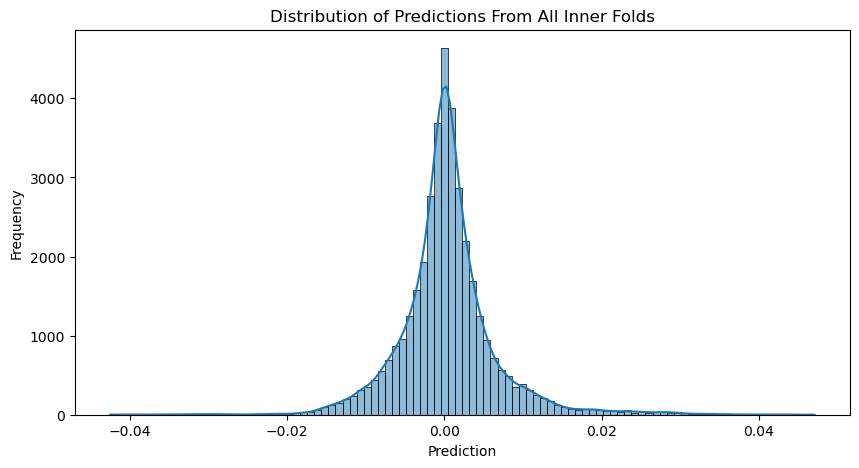

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get all predictions
all_preds = np.concatenate([
    np.concatenate(results["preds_dict"][fold])
    for fold in results["preds_dict"]
])

print('Total Number of Predictions:', all_preds.shape)  # 61 folds * 5 inner folds * 126 samples = 38430 predictions

# Plot distribution
plt.figure(figsize=(10,5))
sns.histplot(all_preds, bins=100, kde=True)
plt.title("Distribution of Predictions From All Inner Folds")
plt.xlabel("Prediction")
plt.ylabel("Frequency")
plt.show()

In [13]:
pd.Series(all_preds).describe()

count    38430.000000
mean         0.000379
std          0.006241
min         -0.042506
25%         -0.002360
50%          0.000126
75%          0.002654
max          0.047086
dtype: float64

In [14]:
def evaluate_multiplier(results, multiplier):
    all_scores = []
    
    for outer_i in results['preds_dict']:
        for inner_j, preds_inner in enumerate(results['preds_dict'][outer_i]):
            solution = results['inner_val_data_dict'][outer_i][inner_j]['solution']
            position = np.clip(preds_inner * multiplier + 1, 0, 2)
            submission = pd.DataFrame({'prediction': position}, index=solution.index)
            score_inner = score(solution, submission, 'index')
            all_scores.append(score_inner)
    
    return np.mean(all_scores)

In [15]:
multipliers = np.linspace(0, 400, 81)  # 0, 5, 10, ..., 400
sharpe_results = {}

for m in multipliers:
    sharpe = evaluate_multiplier(results, m)
    sharpe_results[m] = sharpe
    print(f"Multiplier: {m:.1f}; Corresponding Sharpe: {sharpe:.6f}")

Multiplier: 0.0; Corresponding Sharpe: 0.797206
Multiplier: 5.0; Corresponding Sharpe: 0.821854
Multiplier: 10.0; Corresponding Sharpe: 0.845455
Multiplier: 15.0; Corresponding Sharpe: 0.867110
Multiplier: 20.0; Corresponding Sharpe: 0.886309
Multiplier: 25.0; Corresponding Sharpe: 0.903862
Multiplier: 30.0; Corresponding Sharpe: 0.918992
Multiplier: 35.0; Corresponding Sharpe: 0.931319
Multiplier: 40.0; Corresponding Sharpe: 0.941788
Multiplier: 45.0; Corresponding Sharpe: 0.950971
Multiplier: 50.0; Corresponding Sharpe: 0.959380
Multiplier: 55.0; Corresponding Sharpe: 0.966546
Multiplier: 60.0; Corresponding Sharpe: 0.972773
Multiplier: 65.0; Corresponding Sharpe: 0.978034
Multiplier: 70.0; Corresponding Sharpe: 0.982737
Multiplier: 75.0; Corresponding Sharpe: 0.986676
Multiplier: 80.0; Corresponding Sharpe: 0.989503
Multiplier: 85.0; Corresponding Sharpe: 0.992569
Multiplier: 90.0; Corresponding Sharpe: 0.995685
Multiplier: 95.0; Corresponding Sharpe: 0.996274
Multiplier: 100.0; Cor

In [16]:
best_multiplier = max(sharpe_results, key=sharpe_results.get)
print("\nBest Multiplier:", best_multiplier)
print("Best Sharpe:", sharpe_results[best_multiplier])


Best Multiplier: 105.0
Best Sharpe: 0.9969186110361645


## SHAP
Model-based feature importance ranking

In [17]:
import shap

all_mean_abs = []
all_mean_signed = []

# Loop over each outer fold
for outer_fold in results['inner_models_dict'].keys():

    models = results['inner_models_dict'][outer_fold]  
    val_sets = results['inner_val_data_dict'][outer_fold]
    
    for model_inner, val_data in zip(models, val_sets):
        
        X_val_inner = val_data['X_val']
        
        explainer = shap.TreeExplainer(model_inner)
        shap_values = explainer.shap_values(X_val_inner)
        
        # mean absolute SHAP values (magnitude)
        all_mean_abs.append(np.abs(shap_values).mean(axis=0))
        
        # mean signed SHAP values (direction)
        all_mean_signed.append(shap_values.mean(axis=0))

# Convert from list to arrays
all_mean_abs_arr = np.array(all_mean_abs)
all_mean_signed_arr = np.array(all_mean_signed)

print('Shape of all_mean_abs:', all_mean_abs_arr.shape)
print('Shape of all_mean_signed:', all_mean_signed_arr.shape)

Shape of all_mean_abs: (305, 97)
Shape of all_mean_signed: (305, 97)


In [18]:
# Final aggregated SHAP
mean_abs_shap = np.mean(all_mean_abs_arr, axis=0)
print('Shape of mean_abs_shap:', mean_abs_shap.shape)

mean_signed_shap = np.mean(all_mean_signed_arr, axis=0)
print('Shape of mean_signed_shap:', mean_signed_shap.shape)

# Create DataFrame
direction_df = pd.DataFrame({
    'feature': features,
    'mean_abs_shap': mean_abs_shap,
    'mean_signed_shap': mean_signed_shap
})

direction_df['direction'] = np.where(
    direction_df['mean_signed_shap'] > 0, 'Positive', 'Negative'
)

direction_df = direction_df.sort_values('mean_abs_shap', ascending=False)

Shape of mean_abs_shap: (97,)
Shape of mean_signed_shap: (97,)


In [19]:
direction_df

,feature,mean_abs_shap,mean_signed_shap,direction
17,M9,6.458217e-04,4.186803e-05,Positive
12,M4,4.898182e-04,2.365812e-06,Positive
48,P10,4.835491e-04,2.392723e-04,Positive
31,E3,3.566445e-04,2.560912e-04,Positive
2,M11,3.291818e-04,8.053708e-05,Positive
...,...,...,...,...
87,D3,4.157666e-06,1.161541e-08,Positive
71,V8,2.702339e-06,3.771549e-07,Positive
90,D6,1.673223e-06,1.667583e-08,Positive
88,D4,6.946757e-07,-2.463559e-07,Negative


In [20]:
top_features = direction_df.head(20)['feature'].tolist()
print('Top 20 Features:')
print(top_features)
bottom_features = direction_df.tail(20)['feature'].tolist()
print('\nBottom 20 Features:')
print(bottom_features)

Top 20 Features:
['M9', 'M4', 'P10', 'E3', 'M11', 'V13', 'I8', 'E2', 'P11', 'V7', 'P7', 'P13', 'lagged_risk_free_rate', 'P6', 'M18', 'S5', 'P3', 'P8', 'P4', 'E19']

Bottom 20 Features:
['V12', 'D7', 'E11', 'S1', 'S8', 'S3', 'V11', 'lagged_target', 'M16', 'V1', 'D1', 'E7', 'D8', 'D9', 'D5', 'D3', 'V8', 'D6', 'D4', 'D2']


## Feature Engineering

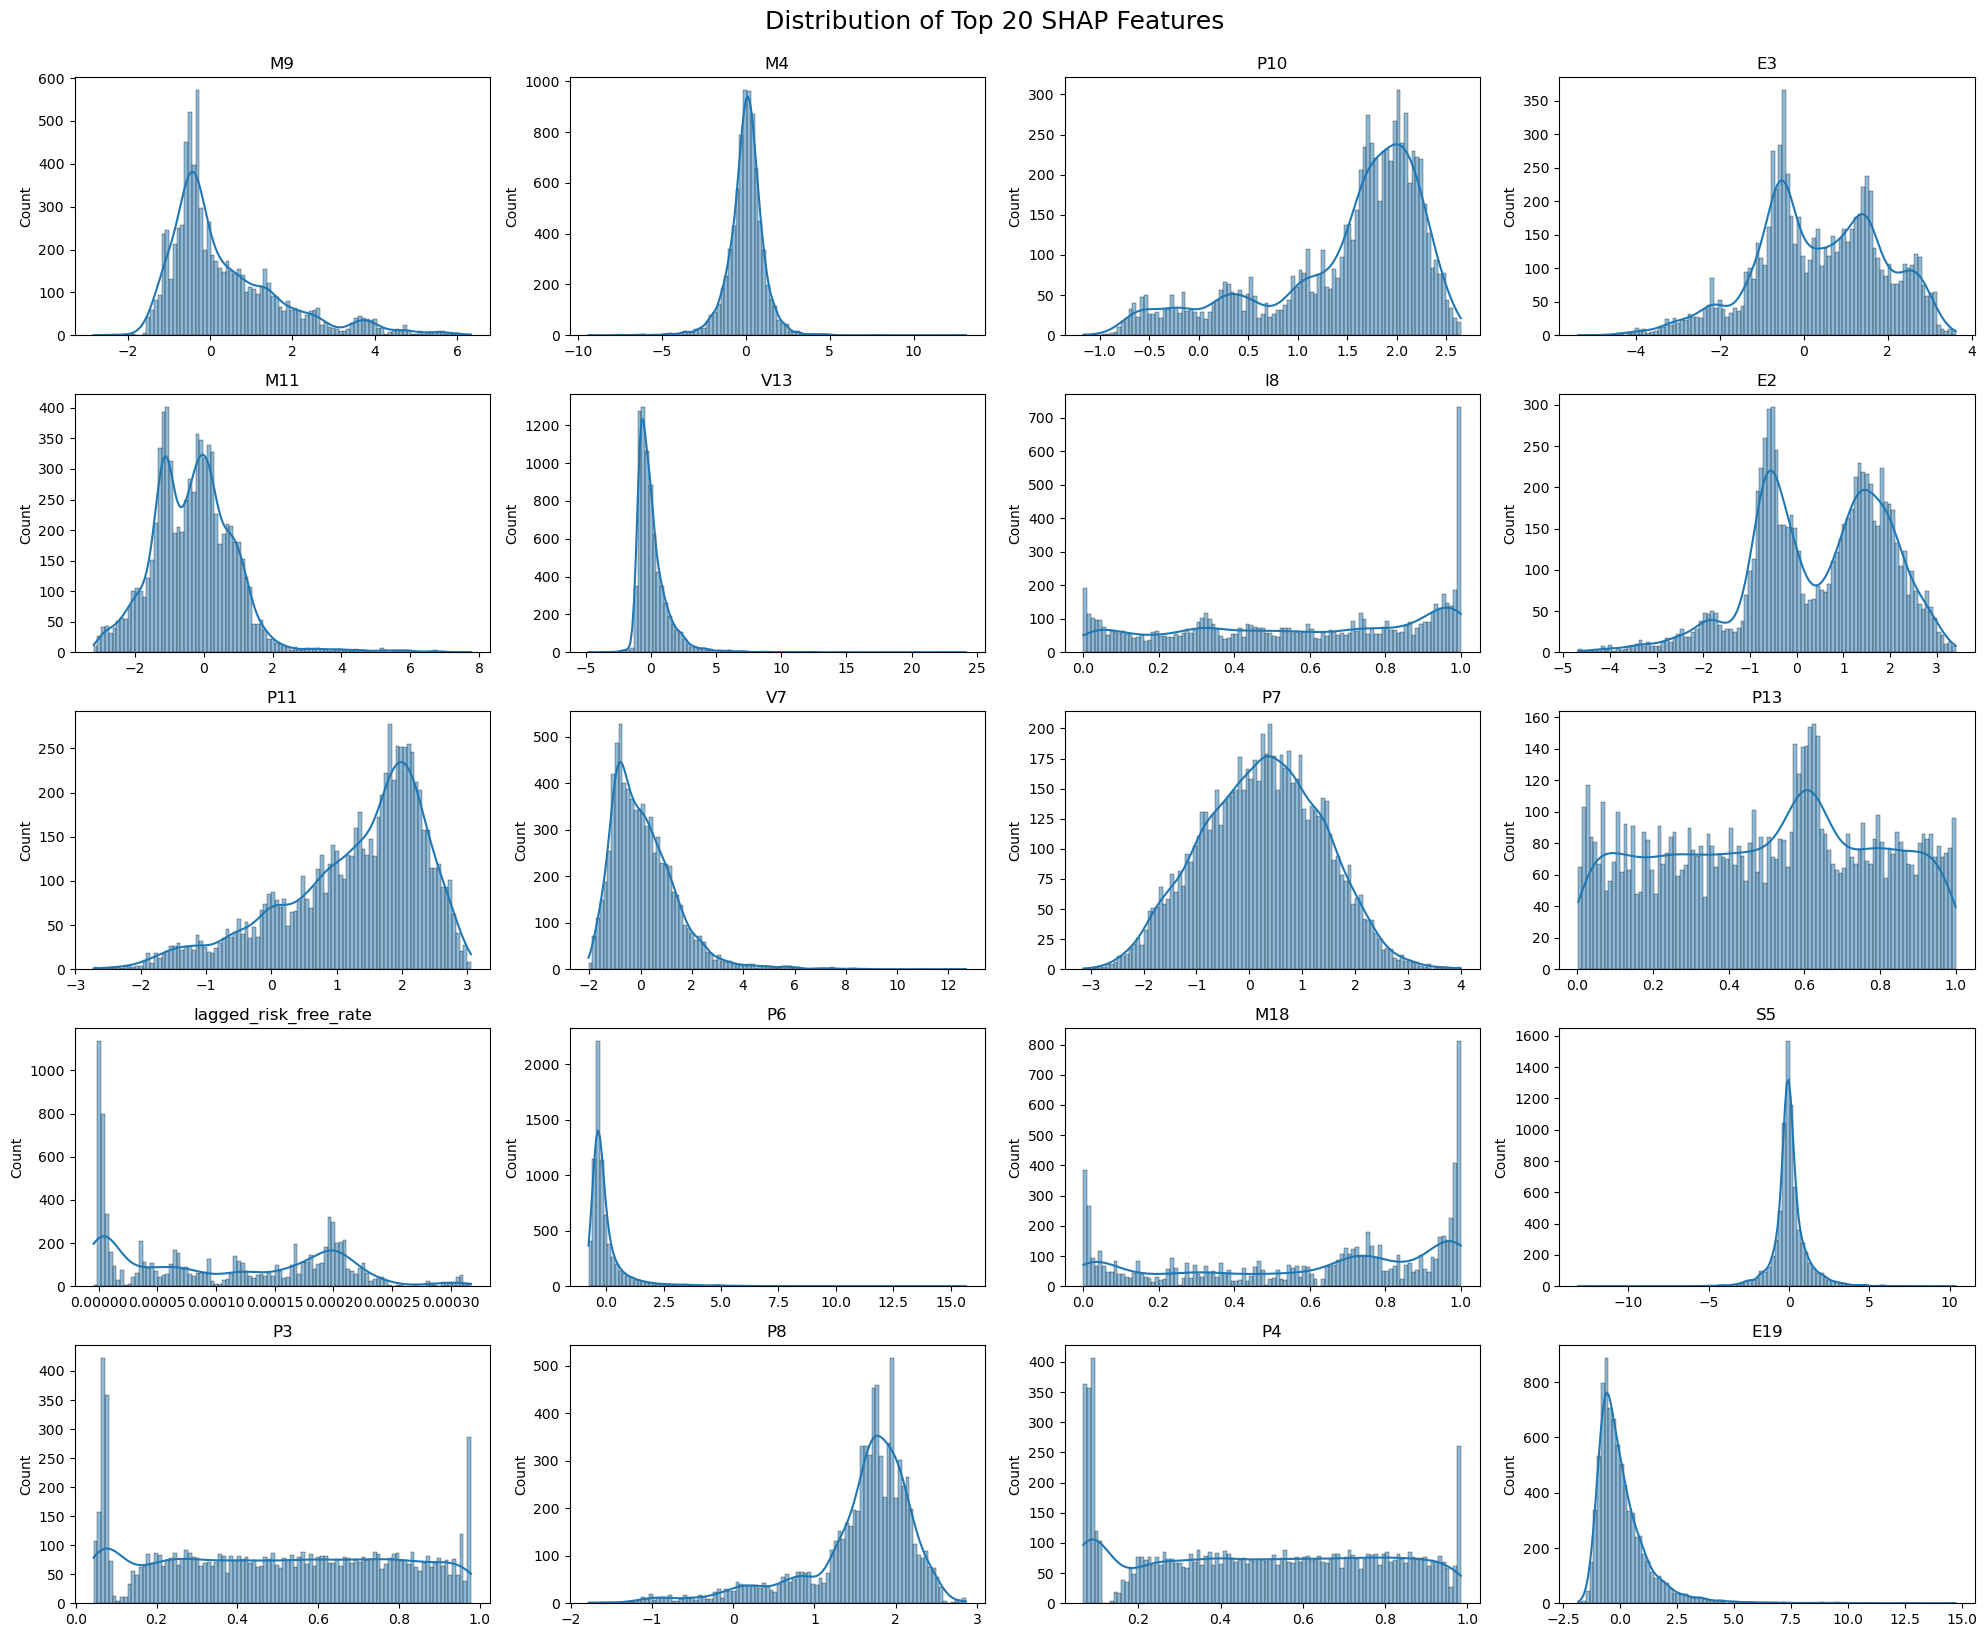

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 16))
num_features = len(top_features)

for i, feature in enumerate(top_features, 1):
    plt.subplot(5, 4, i)
    
    sns.histplot(feature_df[feature], bins=100, kde=True)
    
    plt.title(feature)
    plt.xlabel("")

plt.tight_layout()
plt.suptitle("Distribution of Top 20 SHAP Features", y=1.02, fontsize=18)
plt.show()

### M9

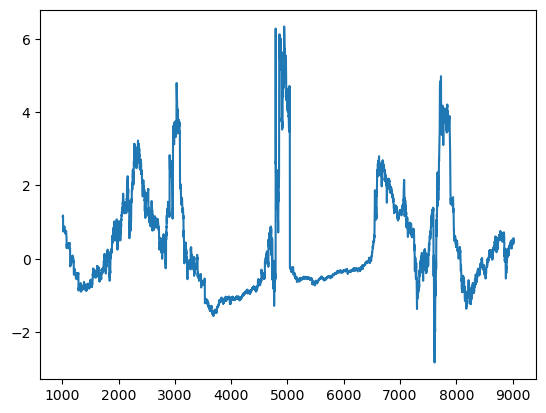

In [22]:
plt.plot(feature_df['M9'])

In [23]:
feature_df['M9'].describe()

count    8015.000000
mean        0.382007
std         1.409160
min        -2.831429
25%        -0.548436
50%        -0.108529
75%         1.047382
max         6.338007
Name: M9, dtype: float64